In [ ]:
!pip install transformers datasets torch scikit-learn

In [ ]:
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from transformers import BertTokenizer, BertForSequenceClassification
from transformers import Trainer, TrainingArguments
from datasets import Dataset

In [ ]:
fake = pd.read_csv("/content/Fake_news.csv")
real = pd.read_csv("/content/True_News.csv")

fake["label"] = 0
real["label"] = 1

data = pd.concat([fake, real])
data = data.sample(frac=1).reset_index(drop=True)

data = data[["text", "label"]]
data.head()

/tmp/ipython-input-2994794417.py:1: DtypeWarning: Columns (4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171) have mixed types. Specify dtype option on import or set low_memory=False.
  fake = pd.read_csv("/content/Fake_news.csv")


,text,label
0,"ERBIL, Iraq/ISTANBUL (Reuters) - Iraq s Kurds ...",1
1,WASHINGTON (Reuters) - White House chief of st...,1
2,We know without a doubt that Trump s blatantly...,0
3,BELFAST (Reuters) - The head of the Democratic...,1
4,"Remember when illegal aliens, students, and re...",0


In [ ]:
train_texts, test_texts, train_labels, test_labels = train_test_split(
    data["text"], data["label"], test_size=0.2, random_state=42
)

In [ ]:
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
train_encodings = tokenizer(
    list(train_texts),
    truncation=True,
    padding=True,
    max_length=256
)

test_encodings = tokenizer(
    list(test_texts),
    truncation=True,
    padding=True,
    max_length=256
)

In [ ]:
train_dataset = Dataset.from_dict({
    "input_ids": train_encodings["input_ids"],
    "attention_mask": train_encodings["attention_mask"],
    "label": list(train_labels)
})

test_dataset = Dataset.from_dict({
    "input_ids": test_encodings["input_ids"],
    "attention_mask": test_encodings["attention_mask"],
    "label": list(test_labels)
})

In [ ]:
model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    #evaluation_strategy="epoch",
    #save_strategy="epoch",
    #logging_dir="./logs",
    #load_best_model_at_end=True
)

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset
)

In [ ]:
trainer.train()

Step,Training Loss
500,0.044535
1000,0.008135
1500,0.004171
2000,0.002426
2500,0.017406
3000,0.008108
3500,0.000061
4000,0.000015
4500,0.000008
5000,0.000005


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (10 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=8984, training_loss=0.004901919015443769, metrics={'train_runtime': 5382.7963, 'train_samples_per_second': 13.352, 'train_steps_per_second': 1.669, 'total_flos': 9454895774361600.0, 'train_loss': 0.004901919015443769, 'epoch': 2.0})

In [ ]:
predictions = trainer.predict(test_dataset)
pred_labels = predictions.predictions.argmax(axis=1)

accuracy = accuracy_score(test_labels, pred_labels)
print("Test Accuracy:", accuracy)

Test Accuracy: 0.9998886910062333


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

In [ ]:
cm = confusion_matrix(test_labels, pred_labels)
print("Confusion Matrix:\n", cm)

# Optional: Classification Report
print("\nClassification Report:\n", classification_report(test_labels, pred_labels))

Confusion Matrix:
 [[4660    0]
 [   1 4323]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      4660
           1       1.00      1.00      1.00      4324

    accuracy                           1.00      8984
   macro avg       1.00      1.00      1.00      8984
weighted avg       1.00      1.00      1.00      8984



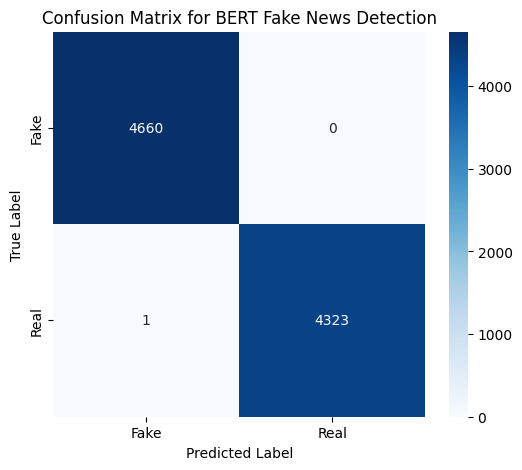

In [ ]:
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Fake','Real'], yticklabels=['Fake','Real'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for BERT Fake News Detection')
plt.show()

In [ ]:
# Install required libraries (run once)
!pip install transformers gradio torch --quiet

# -------------------------
# Imports
# -------------------------
import gradio as gr
import torch
import numpy as np
from transformers import BertTokenizer, BertForSequenceClassification

# -------------------------
# Step 1: Load Tokenizer & Model
# -------------------------
checkpoint_path = "./results/checkpoint-500"  # <-- Replace with your actual checkpoint folder

tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
model = BertForSequenceClassification.from_pretrained(checkpoint_path)
model.eval()  # set model to evaluation mode

# -------------------------
# Step 2: Prediction Function
# -------------------------
def predict_news(text):
    """
    Input: News text (string)
    Output: Prediction label (Real/Fake)
    """
    # Tokenize input
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=256
    )

    # Model prediction
    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
        pred_label = int(torch.argmax(logits, dim=1).item())
        prob = torch.softmax(logits, dim=1)[0][pred_label].item()  # probability

    # Return formatted string
    return f"{'Real News ✅' if pred_label==1 else 'Fake News ❌'} ({prob*100:.2f}% confidence)"

# -------------------------
# Step 3: Gradio Interface with Custom Colors
# -------------------------
app = gr.Interface(
    fn=predict_news,
    inputs=gr.Textbox(
        lines=6,
        placeholder="Paste the news article here...",
        label="News Article"
    ),
    outputs=gr.Textbox(label="Prediction"),
    title="📰 Fake News Detector (BERT Model)",
    description="This BERT-based model predicts whether a news article is Real or Fake. Enter text below and click Submit.",
    theme="default",
    allow_flagging="never"
)

# Custom CSS for better color (background + button)
app.launch()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/gradio/interface.py:415: UserWarning: The `allow_flagging` parameter in `Interface` is deprecated. Use `flagging_mode` instead.
  warnings.warn(


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d6208b543f368a66c3.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
